# Evaluación de métodos de regresión — Estabilidad de redes eléctricas

**Aprendizaje Supervisado · Módulo 2**  
**Autor:** Raúl Pérez

Se comparan regresión lineal, regresión polinomial sin regularización, Ridge polinomial, SVR con kernel RBF y árbol de decisión para predecir `stab`. La evaluación y selección se realizan con validación cruzada de 5 pliegues sobre todo el archivo de entrenamiento disponible.

> **Limitación actual:** `electrical_grid_stability_test.csv` no está disponible. Por ello, este notebook no reporta un RMSE de prueba ficticio. La última sección queda preparada para generar predicciones y solo calcula RMSE si el archivo futuro incluye también las etiquetas `stab`.

## 1. Librerías y carga de datos

Se mantienen los 12 predictores indicados en la consigna. La potencia cumple aproximadamente `p1 = -(p2 + p3 + p4)`, por lo que existe redundancia lineal; se conserva para respetar el planteamiento y se señala al interpretar la regresión lineal. El escalado, cuando corresponde, vive dentro de cada `Pipeline` para que se ajuste solo con los datos de entrenamiento de cada pliegue.

In [23]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

In [ ]:
DATA_DIR = Path.cwd()
TRAIN_PATH = DATA_DIR / "electrical_grid_stability_train.csv"
if not TRAIN_PATH.is_file():
    raise FileNotFoundError(
        f"No se encontró {TRAIN_PATH}. Ajusta TRAIN_PATH a la ubicación exacta del .csv de entrenamiento."
    )



In [25]:
df = pd.read_csv(TRAIN_PATH)
df.head()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871
4,6.999209,9.109247,3.784066,4.267788,4.429669,-1.857139,-0.670397,-1.902133,0.261793,0.077930,0.542884,0.469931,-0.017385


In [27]:
feature_cols = ["tau1","tau2","tau3","tau4","p1","p2","p3","p4","g1","g2","g3","g4"]
target_col = "stab"

X = df[feature_cols].copy()
y = df[target_col].copy()
print(f"(filas,columnas): {df.shape}")

(filas,columnas): (8000, 13)


## 2. Análisis exploratorio y calidad de datos

Se revisan tipos, faltantes, duplicados, rangos, asociación lineal y observaciones señaladas por la regla exploratoria de 1.5 × IQR. Esa regla solo identifica valores para inspección: no se eliminan filas sin evidencia de errores, pues los extremos pueden ser estados válidos de la simulación.

In [28]:
df.dtypes

tau1    float64
tau2    float64
tau3    float64
tau4    float64
p1      float64
p2      float64
p3      float64
p4      float64
g1      float64
g2      float64
g3      float64
g4      float64
stab    float64
dtype: object

In [6]:
df.isna().sum()

tau1    0
tau2    0
tau3    0
tau4    0
p1      0
p2      0
p3      0
p4      0
g1      0
g2      0
g3      0
g4      0
stab    0
dtype: int64

In [29]:
df.duplicated().sum()

np.int64(0)

In [31]:
df.describe().round(2)

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00
mean,5.24,5.24,5.25,5.24,3.75,-1.25,-1.25,-1.25,0.52,0.52,0.53,0.53,0.02
std,2.74,2.75,2.74,2.76,0.76,0.43,0.43,0.43,0.27,0.27,0.27,0.27,0.04
min,0.50,0.50,0.50,0.50,1.58,-2.00,-2.00,-2.00,0.05,0.05,0.05,0.05,-0.08
25%,2.87,2.84,2.88,2.86,3.22,-1.62,-1.62,-1.63,0.28,0.28,0.29,0.29,-0.02
50%,5.23,5.25,5.25,5.25,3.75,-1.25,-1.25,-1.25,0.52,0.52,0.53,0.53,0.02
75%,7.60,7.63,7.63,7.62,4.29,-0.88,-0.88,-0.88,0.76,0.76,0.76,0.77,0.04
max,10.00,10.00,10.00,10.00,5.83,-0.50,-0.50,-0.50,1.00,1.00,1.00,1.00,0.11


In [33]:
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
outlier_counts = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum()
outlier_counts.rename("conteo").to_frame()

,conteo
tau1,0
tau2,0
tau3,0
tau4,0
p1,1
p2,0
p3,0
p4,0
g1,0
g2,0


In [34]:
balance_error = (df["p1"] + df["p2"] + df["p3"] + df["p4"]).abs()
print(f"\nMáximo |p1 + p2 + p3 + p4|: {balance_error.max():.2e}")
print(f"stab < 0: {(y < 0).sum():,} | stab > 0: {(y > 0).sum():,}")


Máximo |p1 + p2 + p3 + p4|: 1.00e-09
stab < 0: 2,915 | stab > 0: 5,085


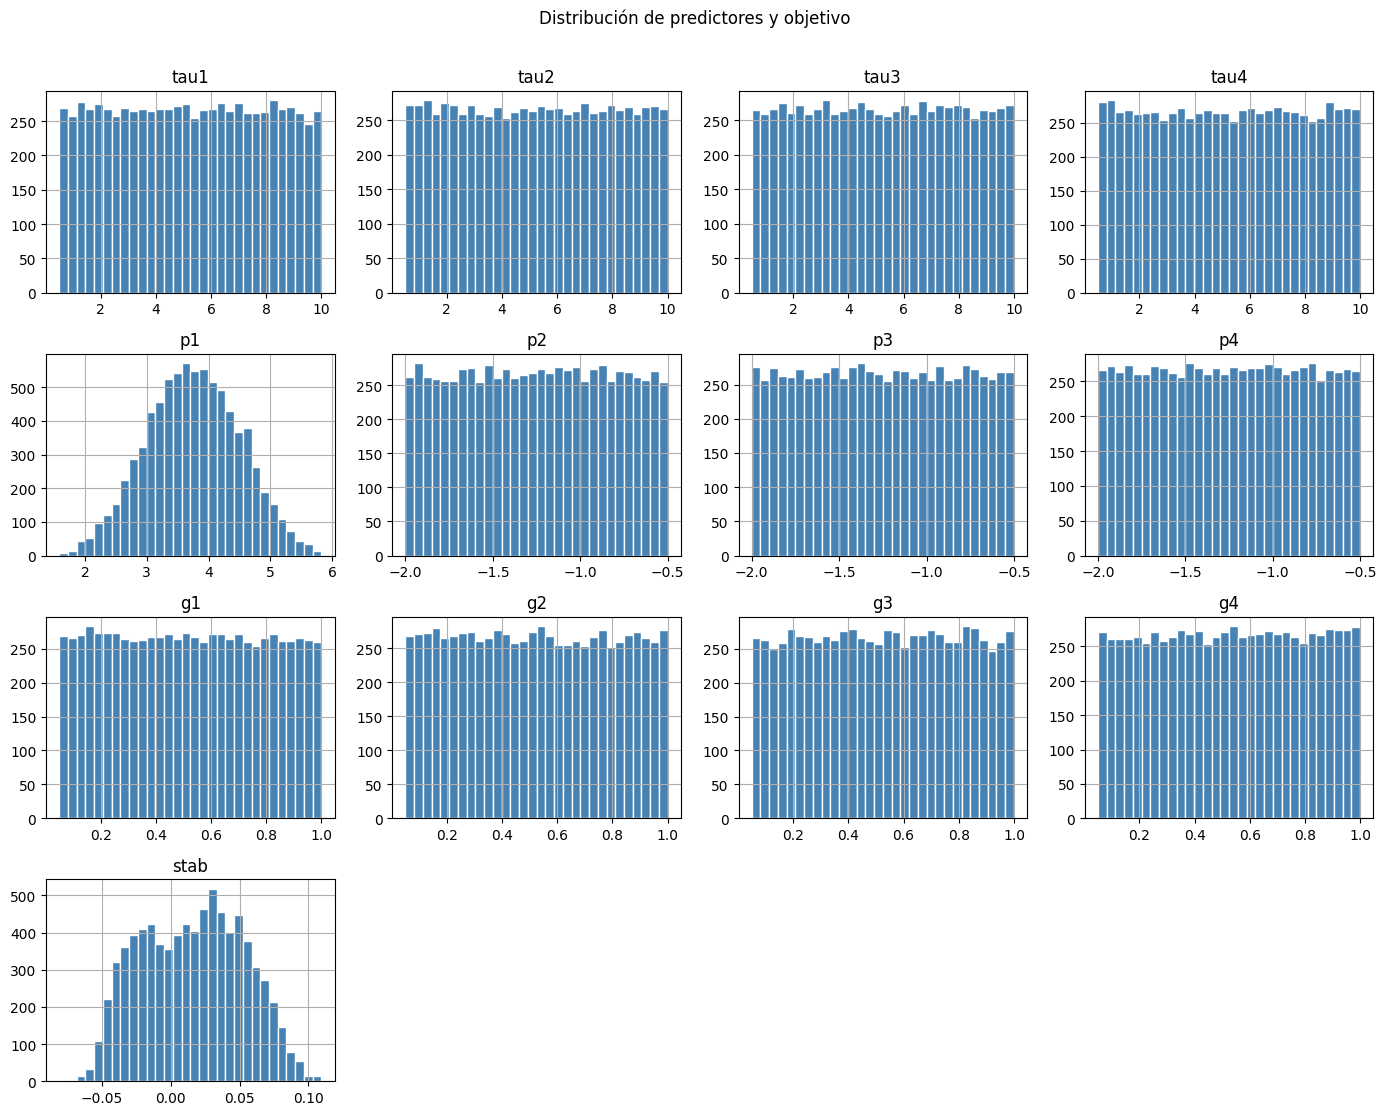

In [35]:
axes = df.hist(bins=30, figsize=(14, 11), color="steelblue", edgecolor="white")
plt.suptitle("Distribución de predictores y objetivo", y=1.01)
plt.tight_layout()
plt.show()

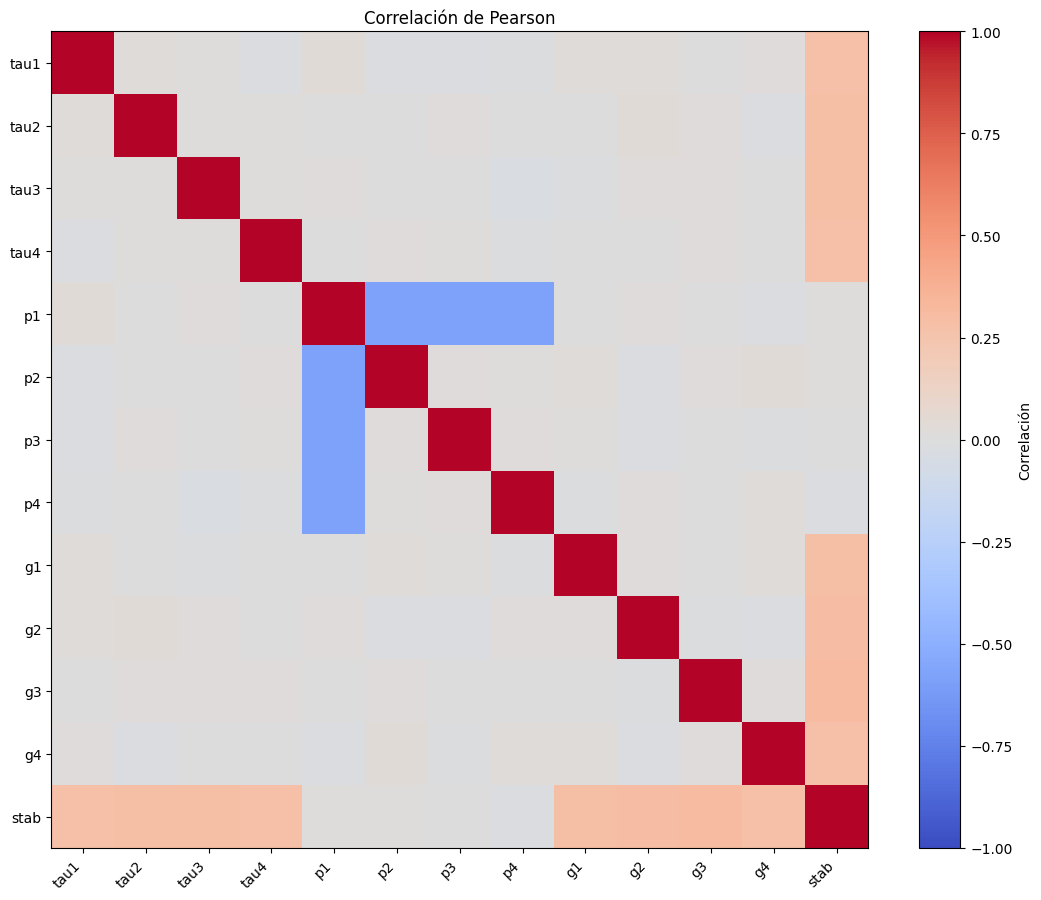

In [ ]:
correlations = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(expected_cols)), expected_cols, rotation=45, ha="right")
ax.set_yticks(range(len(expected_cols)), expected_cols)
ax.set_title("Correlación de Pearson")
fig.colorbar(image, ax=ax, label="Correlación")
fig.tight_layout()
plt.show()

In [37]:
print("Correlación con stab (orden descendente):")
display(correlations[target_col].drop(target_col).sort_values(ascending=False).to_frame("correlación"))

Correlación con stab (orden descendente):


,correlación
g3,0.309345
g2,0.291744
tau2,0.286032
g1,0.283376
tau3,0.282431
tau4,0.280353
g4,0.277858
tau1,0.277081
p1,0.007605
p2,0.005483


### Lectura del EDA

La tabla y las gráficas anteriores permiten documentar rangos y forma de las distribuciones. La restricción de balance de potencia se verifica numéricamente; por ello, los cuatro predictores `p` no aportan cuatro grados de libertad independientes. La correlación de Pearson describe solo asociación lineal y no descarta relaciones no lineales. No se imputan ni eliminan observaciones automáticamente: el diagnóstico de faltantes/duplicados y los conteos IQR se revisan antes de entrenar.

## 3. Protocolo de evaluación

Se usa `KFold` de 5 pliegues, con barajado y semilla fija para reproducibilidad. RMSE es la métrica principal; también se informan MAE y R². En las búsquedas, se selecciona la configuración por RMSE medio de los mismos cinco pliegues y se informa su media y desviación estándar. Como la selección y el reporte usan esos pliegues, los resultados sirven para comparación académica y pueden ser algo optimistas; no son una evaluación independiente de prueba.

In [15]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}
results = []
selected_models = {}

def summarize_cv(name, scores, params=None):
    """Guarda métricas de los cinco pliegues en la orientación habitual."""
    results.append({
        "Modelo": name,
        "RMSE media": -scores["test_rmse"].mean(),
        "RMSE std": scores["test_rmse"].std(),
        "MAE media": -scores["test_mae"].mean(),
        "MAE std": scores["test_mae"].std(),
        "R² media": scores["test_r2"].mean(),
        "R² std": scores["test_r2"].std(),
        "Hiperparámetros": params or {},
    })

def run_search(name, estimator, param_grid):
    """Ajusta hiperparámetros y recupera las métricas por pliegue del ganador."""
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring=scoring,
        refit="rmse",
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
    )
    search.fit(X, y)
    index = search.best_index_
    fold_scores = {
        "test_rmse": np.array([search.cv_results_[f"split{i}_test_rmse"][index] for i in range(cv.get_n_splits())]),
        "test_mae": np.array([search.cv_results_[f"split{i}_test_mae"][index] for i in range(cv.get_n_splits())]),
        "test_r2": np.array([search.cv_results_[f"split{i}_test_r2"][index] for i in range(cv.get_n_splits())]),
    }
    summarize_cv(name, fold_scores, search.best_params_)
    return search.best_estimator_, search.best_params_


## 4. Regresión lineal y polinomial sin regularización

La regresión lineal se evalúa como referencia. En la regresión polinomial se exploran grados 2 y 3; la expansión y el escalado se incluyen en el `Pipeline`, de modo que cada pliegue aprende las transformaciones únicamente con su subconjunto de entrenamiento.

In [16]:
linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_scores = cross_validate(linear_model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
summarize_cv("Regresión lineal", linear_scores)
selected_models["Regresión lineal"] = linear_model

polynomial_models = {}
for degree in (2, 3):
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )
    scores = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    name = f"Polinomial sin regularización (grado {degree})"
    summarize_cv(name, scores, {"grado": degree})
    polynomial_models[degree] = model

best_degree = min(
    (2, 3),
    key=lambda degree: next(row["RMSE media"] for row in results if row["Modelo"] == f"Polinomial sin regularización (grado {degree})"),
)
selected_models["Polinomial sin regularización"] = polynomial_models[best_degree]
print(f"\nGrado seleccionado por RMSE medio de CV: {best_degree}")


Grado seleccionado por RMSE medio de CV: 3


## 5. Regresión polinomial con regularización Ridge

Ridge penaliza los coeficientes grandes (L2), útil al crear términos polinomiales correlacionados. Se buscan el grado y `alpha`; el escalado se ajusta dentro del flujo de cada pliegue.

In [17]:
ridge_pipeline = make_pipeline(
    PolynomialFeatures(include_bias=False),
    StandardScaler(),
    Ridge(),
)
ridge_model, ridge_params = run_search(
    "Ridge polinomial",
    ridge_pipeline,
    {
        "polynomialfeatures__degree": [2, 3],
        "ridge__alpha": [0.1, 1.0, 10.0, 100.0],
    },
)
selected_models["Ridge polinomial"] = ridge_model
print("Mejores hiperparámetros:", ridge_params)

Mejores hiperparámetros: {'polynomialfeatures__degree': 3, 'ridge__alpha': 0.1}


## 6. Support Vector Regression (SVR)

El kernel RBF modela relaciones no lineales. Se escalan las entradas dentro del `Pipeline` y se ajustan `C`, `epsilon` y `gamma` por búsqueda en rejilla.

In [18]:
svr_pipeline = make_pipeline(StandardScaler(), SVR(kernel="rbf"))
svr_model, svr_params = run_search(
    "SVR RBF",
    svr_pipeline,
    {
        "svr__C": [1, 10],
        "svr__epsilon": [0.01, 0.1],
        "svr__gamma": ["scale", 0.1],
    },
)
selected_models["SVR RBF"] = svr_model
print("Mejores hiperparámetros:", svr_params)

Mejores hiperparámetros: {'svr__C': 1, 'svr__epsilon': 0.01, 'svr__gamma': 'scale'}


## 7. Árbol de decisión para regresión

Se limitan profundidad y tamaño mínimo de hoja para reducir el sobreajuste. Los árboles no requieren escalado; la selección de los criterios de poda se hace con la misma validación cruzada.

In [19]:
tree_model, tree_params = run_search(
    "Árbol de decisión",
    DecisionTreeRegressor(random_state=42),
    {
        "max_depth": [4, 8, 12],
        "min_samples_leaf": [5, 20],
    },
)
selected_models["Árbol de decisión"] = tree_model
print("Mejores hiperparámetros:", tree_params)

Mejores hiperparámetros: {'max_depth': 12, 'min_samples_leaf': 20}


## 8. Comparación de modelos y conclusión

La tabla presenta media y desviación estándar entre los cinco pliegues. Se ordena por RMSE medio, que es la métrica principal. Las variantes polinomiales de grados 2 y 3 aparecen por separado para transparentar la exploración solicitada.

In [20]:
results_df = pd.DataFrame(results).sort_values("RMSE media").reset_index(drop=True)
display(results_df)

best_row = results_df.iloc[0]
print(
    f"Mejor resultado de CV: {best_row['Modelo']} — "
    f"RMSE = {best_row['RMSE media']:.6f} ± {best_row['RMSE std']:.6f}, "
    f"MAE = {best_row['MAE media']:.6f}, R² = {best_row['R² media']:.6f}."
)
print(
    "Esta comparación no sustituye una evaluación independiente: las configuraciones "
    "se seleccionaron usando los mismos pliegues cuyo desempeño se reporta."
)

,Modelo,RMSE media,RMSE std,MAE media,MAE std,R² media,R² std,Hiperparámetros
0,Ridge polinomial,0.008717,0.000162,0.006111,0.000070,0.944267,0.002794,"{'polynomialfeatures__degree': 3, 'ridge__alph..."
1,Polinomial sin regularización (grado 3),0.008720,0.000168,0.006119,0.000072,0.944228,0.002859,{'grado': 3}
2,SVR RBF,0.009028,0.000112,0.006722,0.000056,0.940245,0.001887,"{'svr__C': 1, 'svr__epsilon': 0.01, 'svr__gamm..."
3,Polinomial sin regularización (grado 2),0.012336,0.000122,0.009291,0.000111,0.888406,0.004056,{'grado': 2}
4,Árbol de decisión,0.018745,0.000421,0.014659,0.000211,0.742130,0.016093,"{'max_depth': 12, 'min_samples_leaf': 20}"
5,Regresión lineal,0.022088,0.000473,0.017537,0.000447,0.642199,0.017597,{}


Mejor resultado de CV: Ridge polinomial — RMSE = 0.008717 ± 0.000162, MAE = 0.006111, R² = 0.944267.
Esta comparación no sustituye una evaluación independiente: las configuraciones se seleccionaron usando los mismos pliegues cuyo desempeño se reporta.


## 9. Predicciones para test.csv (pendiente de recibir el archivo)

Cuando se coloque `electrical_grid_stability_test.csv` junto al notebook, esta celda ajustará cada configuración seleccionada con las 8,000 filas etiquetadas y guardará una columna de predicciones por modelo en `predicciones_stab_test.csv`. Si el archivo no incluye `stab` (como indica la consigna), no se puede calcular RMSE: el archivo de salida contendrá predicciones, no métricas de prueba. Si en el futuro se entrega un test con etiquetas, se imprimirán RMSE, MAE y R².

In [21]:
TEST_PATH = DATA_DIR / "electrical_grid_stability_test.csv"
PREDICTIONS_PATH = DATA_DIR / "predicciones_stab_test.csv"

if not TEST_PATH.is_file():
    print(f"Test pendiente: no se encontró {TEST_PATH.name}. No se generan predicciones ni RMSE de prueba.")
else:
    test_df = pd.read_csv(TEST_PATH)
    missing_test_cols = sorted(set(feature_cols) - set(test_df.columns))
    if missing_test_cols:
        raise ValueError(f"Faltan predictores en el archivo de prueba: {missing_test_cols}")

    X_test = test_df[feature_cols]
    prediction_frame = pd.DataFrame(index=test_df.index)
    for model_name, estimator in selected_models.items():
        fitted_model = clone(estimator).fit(X, y)
        prediction_frame[f"stab_pred_{model_name}"] = fitted_model.predict(X_test)

    prediction_frame.to_csv(PREDICTIONS_PATH, index=False)
    print(f"Predicciones guardadas en: {PREDICTIONS_PATH}")

    if target_col in test_df.columns:
        y_test = test_df[target_col]
        for column in prediction_frame.columns:
            print(
                f"{column}: RMSE={mean_squared_error(y_test, prediction_frame[column]) ** 0.5:.6f} | "
                f"MAE={mean_absolute_error(y_test, prediction_frame[column]):.6f} | "
                f"R²={r2_score(y_test, prediction_frame[column]):.6f}"
            )
    else:
        print("El archivo no contiene 'stab'; las métricas RMSE/MAE/R² de prueba no son calculables.")

Test pendiente: no se encontró electrical_grid_stability_test.csv. No se generan predicciones ni RMSE de prueba.
